# Shanghai real estate prices and distance to the subway

**Question:** is the price per square metre of an apartment in Shanghai correlated with its distance to the nearest subway station, and by how much does it vary for each metre away from the station?

Course project — TSH00, UTSEUS (Shanghai University).

Data:
- **Anjuke** real estate listings (2017), ~467,000 apartments for sale in Shanghai
- **Gaode (AutoNavi)** points of interest (2017), used to locate subway station entrances

*The datasets were provided for the course and are not redistributed in this repository.*

In [1]:
# import data science libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt



# import advanced plot drawing library
import seaborn as sns 

# import data science library with added geographic functions
import geopandas as gpd

# useful to calculate the Ordinary Least Square linear regression
import statsmodels 

# useful to get fast distance calculation, 
# see https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.BallTree.html
from sklearn.neighbors import BallTree 

# useful to access functions like median, mean or std 
from scipy import stats 

# basemaps
import contextily as cx

sns.set_style("white")

## 1 – Real estate listings (Anjuke)

The dataset was collected by UTSEUS in 2017 from [anjuke.com](https://shanghai.anjuke.com/sale). It is stored as a pickle file: a list of lists whose first item contains the column names.

In [2]:
real_estate_file = 'data/utseus-anjuke-real-estate.pk'
anjuke = pd.read_pickle(real_estate_file)

In [3]:
anjuke_df = pd.DataFrame(anjuke[1:],columns=anjuke[0], )


### Data types

All columns are imported as text (`object`), so the numeric columns must be converted before any calculation.

In [4]:
anjuke_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467029 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   id              467029 non-null  object
 1   address         467029 non-null  object
 2   longitude       467029 non-null  object
 3   latitude        467029 non-null  object
 4   bedroom         467029 non-null  object
 5   room            467029 non-null  object
 6   surface         467029 non-null  object
 7   price           467029 non-null  object
 8   onesquaremeter  467029 non-null  object
 9   tags            467029 non-null  object
 10  district        467029 non-null  object
 11  neighborhood    467029 non-null  object
 12  done            467029 non-null  object
dtypes: object(13)
memory usage: 46.3+ MB


In [5]:
numeric_columns = ['longitude', 'latitude', 'bedroom', 'room', 'surface', 'price', 'onesquaremeter']
anjuke_df[numeric_columns] = anjuke_df[numeric_columns].apply(pd.to_numeric)

anjuke_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 467029 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              467029 non-null  object 
 1   address         467029 non-null  object 
 2   longitude       463067 non-null  float64
 3   latitude        463067 non-null  float64
 4   bedroom         467029 non-null  int64  
 5   room            467029 non-null  int64  
 6   surface         467029 non-null  float64
 7   price           467029 non-null  float64
 8   onesquaremeter  467029 non-null  float64
 9   tags            467029 non-null  object 
 10  district        467029 non-null  object 
 11  neighborhood    467029 non-null  object 
 12  done            467029 non-null  object 
dtypes: float64(5), int64(2), object(6)
memory usage: 46.3+ MB


Rows whose coordinates could not be converted (3,962 listings) are dropped.

In [6]:
anjuke_df = anjuke_df.dropna()

In [7]:
anjuke_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 463067 entries, 0 to 467028
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   id              463067 non-null  object 
 1   address         463067 non-null  object 
 2   longitude       463067 non-null  float64
 3   latitude        463067 non-null  float64
 4   bedroom         463067 non-null  int64  
 5   room            463067 non-null  int64  
 6   surface         463067 non-null  float64
 7   price           463067 non-null  float64
 8   onesquaremeter  463067 non-null  float64
 9   tags            463067 non-null  object 
 10  district        463067 non-null  object 
 11  neighborhood    463067 non-null  object 
 12  done            463067 non-null  object 
dtypes: float64(5), int64(2), object(6)
memory usage: 49.5+ MB


### Geographic conversion

The longitude/latitude columns are converted into point geometries (GeoDataFrame, WGS84) to allow spatial operations.

In [8]:
anjuke_gdf = gpd.GeoDataFrame(
        anjuke_df, 
        geometry=gpd.points_from_xy(anjuke_df.longitude, anjuke_df.latitude), crs=4326)

<Axes: >

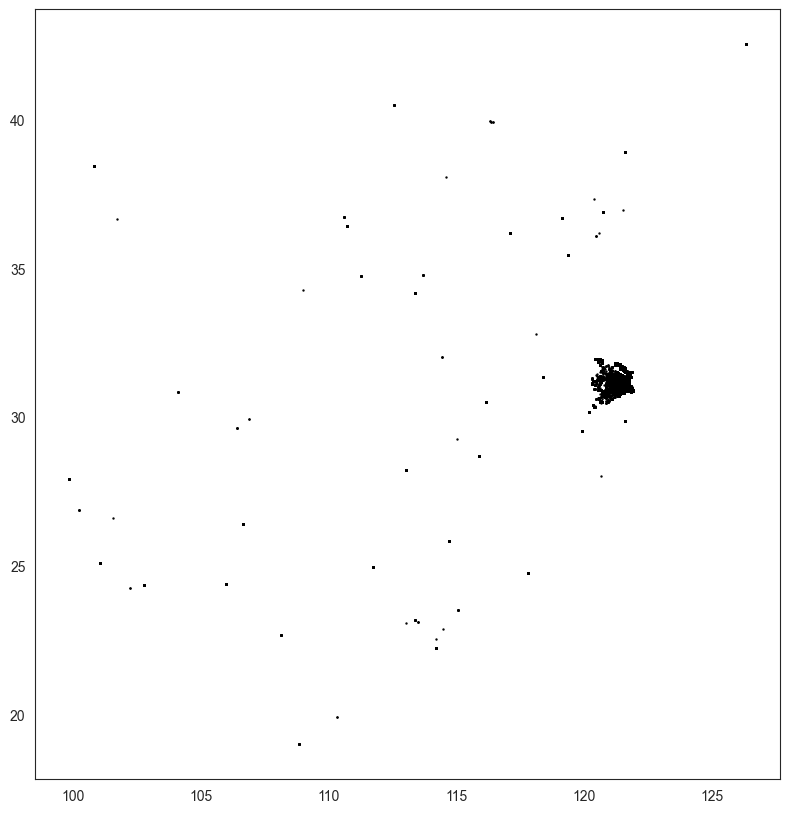

In [9]:
anjuke_gdf.plot(
    markersize=0.5,
    figsize=(10, 10), 
    color='black'
)

The map shows that some listings are located **far outside Shanghai**. This can come from wrong GPS coordinates entered by sellers, or from listings of nearby cities included in the source website. The total bounds confirm it:

In [10]:
anjuke_gdf.total_bounds

array([ 99.82410591,  18.99369628, 126.33039253,  42.54940926])

### Restricting the data to Shanghai

The listings are filtered with a bounding box around the Shanghai municipality (found with [bboxfinder.com](http://bboxfinder.com/)).

In [12]:
print(f'before {len(anjuke_gdf)}')

west = 120.85   
east = 122.12   
south = 30.66   
north = 31.88   

anjuke_filterbb_gdf = anjuke_gdf[
    anjuke_gdf['latitude'].between(south, north) & 
    anjuke_gdf['longitude'].between(west, east)
]

print(f'after {len(anjuke_filterbb_gdf)}')


before 463067
after 454049


### Coordinate check

Chinese maps often use the GCJ-02 coordinate system, shifted from GPS (WGS84). Plotting the listings on a basemap around the city centre and the Huangpu river allows us to check that the coordinates are consistent.

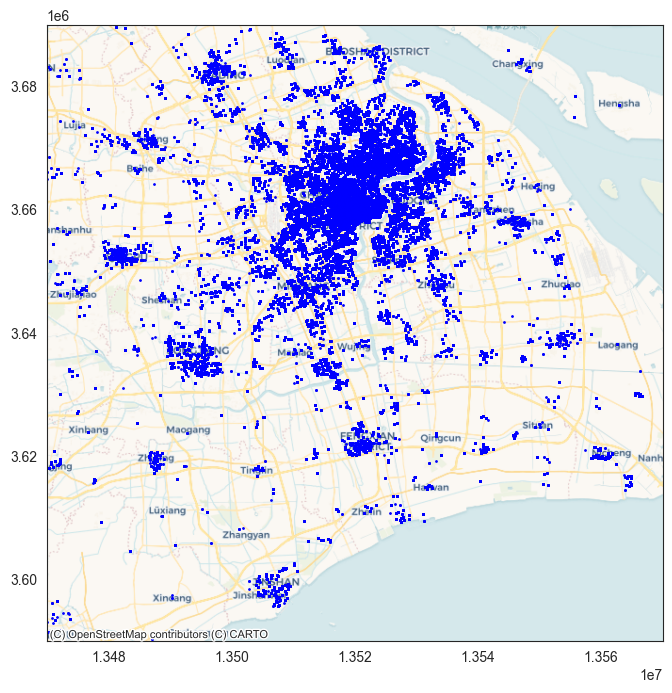

In [22]:
# Créer le plot initial
ax = anjuke_filterbb_gdf.to_crs(3857).plot(markersize=1, color='b', figsize=(8,8))

# Définir les limites pour centrer sur Shanghai
# Coordonnées en EPSG:3857 (Web Mercator)
shanghai_center_x = 13520000  # Longitude 121.4737° E
shanghai_center_y = 3640000   # Latitude 31.2304° N

# Définir la taille de la fenêtre (ajustez ces valeurs pour zoomer/dézoomer)
window_size = 50000  # en mètres

# Appliquer les limites
ax.set_xlim(shanghai_center_x - window_size, shanghai_center_x + window_size)
ax.set_ylim(shanghai_center_y - window_size, shanghai_center_y + window_size)

# Ajouter la carte de base
cx.add_basemap(ax, source=cx.providers.CartoDB.Voyager)

## 2 – Subway stations (Gaode POI)

The points of interest come from Gaode (AutoNavi), 2017 edition, to be consistent with the real estate data.

In [14]:
poi_df = pd.read_csv('data/shanghaiPOI2017.csv',delimiter=';', decimal=',', low_memory=False)

In [15]:
poi_df.columns


Index(['Unnamed: 0', 'ID', 'POIID', 'GCJX', 'GCJY', 'NAME', 'ADD', 'TEL',
       'TYPE', 'AREAID', 'IDKEY', 'GPSX', 'GPSY', 'TYPE1', 'TYPE2', 'TYPE3',
       'TYPE4', 'TYPE5', 'TYPE3.1', 'TYPE3.2', 'TYPE3.3', 'TYPE1.N', 'TYPE2.N',
       'TYPE3.N', 'TYPE3.1.N', 'TYPECODE', 'GBCODE'],
      dtype='object')

Subway stations are identified by searching for 地铁站 ("subway station") in the category description.

In [ ]:
poi_df[poi_df.TYPECODE.str.contains('地铁站')].loc[:,['TYPECODE','GBCODE']]


,TYPECODE,GBCODE
69644,交通设施服务;地铁站;出入口,200402.0
69645,交通设施服务;地铁站;出入口,200402.0
69646,交通设施服务;地铁站;出入口,200402.0
69647,交通设施服务;地铁站;出入口,200402.0
69648,交通设施服务;地铁站;出入口,200402.0
...,...,...
71345,交通设施服务;地铁站;地铁站,200401.0
71346,交通设施服务;地铁站;地铁站,200401.0
71347,交通设施服务;地铁站;地铁站,200401.0
71348,交通设施服务;地铁站;地铁站,200401.0


Two national GB codes (standard [GB/T 35648-2017](https://openstd.samr.gov.cn/bzgk/gb/newGbInfo?hcno=3330BB5A1FF81A61F8A7432B0BB4AE01)) correspond to the subway: **200401** (station) and **200402** (station entrance). We keep the **entrances** (200402), which better represent the actual walking access point.

In [55]:
GBCODE = 200402.0  # subway station entrances
poi_subway_df = poi_df[poi_df.GBCODE == GBCODE]
poi_subway_df["GPSX"]

69644    121.314403
69645    121.313594
69646    121.315250
69647    121.343555
69648    121.228284
            ...    
70924    121.518659
70925    121.518028
70926    121.271702
70927    121.271755
70928    121.272921
Name: GPSX, Length: 1285, dtype: float64

The entrances are converted into a GeoDataFrame and mapped.

In [56]:
poi_subway_gdf = gpd.GeoDataFrame(
    poi_subway_df,
    geometry=gpd.points_from_xy(poi_subway_df.GPSX, poi_subway_df.GPSY),
    crs="EPSG:4326" 
)

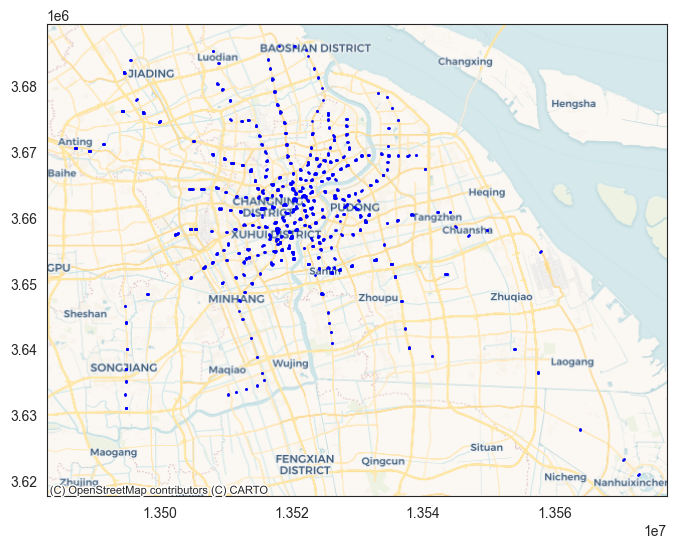

In [57]:
poi_subway_gdf_3857 = poi_subway_gdf.to_crs(epsg=3857)


fig, ax = plt.subplots(figsize=(8, 8))


poi_subway_gdf_3857.plot(ax=ax, markersize=1, color='b')
cx.add_basemap(ax, source=cx.providers.CartoDB.Voyager)
plt.show()

## 3 – Distance to the nearest subway entrance

For each listing, we compute the distance to the closest subway entrance. The computation is vectorised with `shapely.distance` (a first loop-based version was far too slow for 450,000 listings).

*Note: distances are computed in WGS84 coordinates, so they are expressed in **degrees**. In Shanghai (latitude ≈ 31°), 1 degree ≈ 95 km east–west and 111 km north–south, i.e. roughly **100 km**.*

In [31]:
list_exit_points = poi_subway_gdf.geometry.to_numpy()

In [ ]:
def distance_to_subway(p1):
    distances = distance(p1,list_exit_points)
    return min(distances)

In [34]:
anjuke_filterbb_gdf['closest'] = anjuke_filterbb_gdf.geometry.apply(distance_to_subway)

In [35]:
anjuke_filterbb_gdf.closest.describe()

count    454049.000000
mean          0.054169
std           0.054859
min           0.000058
25%           0.024935
50%           0.039360
75%           0.054673
max           0.500361
Name: closest, dtype: float64

## 4 – Linear regression

We remove extreme prices, then fit an ordinary least squares regression of the price per square metre on the distance to the nearest subway entrance.

<Axes: xlabel='closest', ylabel='onesquaremeter'>

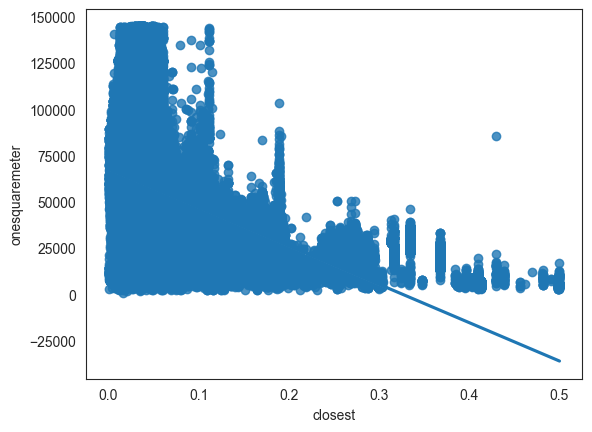

In [39]:
data_no_outliers = anjuke_filterbb_gdf[
(anjuke_filterbb_gdf.onesquaremeter < 3*anjuke_filterbb_gdf.onesquaremeter.std() )&
(anjuke_filterbb_gdf.onesquaremeter > -3*anjuke_filterbb_gdf.onesquaremeter.std())]

sns.regplot(x='closest', y='onesquaremeter', data=data_no_outliers, ci=95)

In [40]:
import statsmodels.formula.api as smf


model = smf.ols(formula = 'onesquaremeter ~ closest', data=data_no_outliers).fit()



In [41]:
model.rsquared

0.17537611576274825

In [42]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:         onesquaremeter   R-squared:                       0.175
Model:                            OLS   Adj. R-squared:                  0.175
Method:                 Least Squares   F-statistic:                 9.560e+04
Date:                Tue, 29 Apr 2025   Prob (F-statistic):               0.00
Time:                        10:39:34   Log-Likelihood:            -5.1855e+06
No. Observations:              449514   AIC:                         1.037e+07
Df Residuals:                  449512   BIC:                         1.037e+07
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   6.763e+04     51.868   1303.939      0.000    6.75e+04    6.77e+04
closest    -2.072e+05    670.230   -309.192      0.000   -2.09e+05   -2.06e+05
==============================================================================
Omnibus:                    19763.396   Durbin-Watson:                   0.563
Prob(Omnibus):                  0.000   Jarque-Bera (JB):            23070.446
Skew:                           0.507   Prob(JB):                         0.00
Kurtosis:                       3.451   Cond. No.                         18.2
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [43]:
residuals = model.predict(data_no_outliers.closest) - data_no_outliers.onesquaremeter

<Axes: ylabel='Count'>

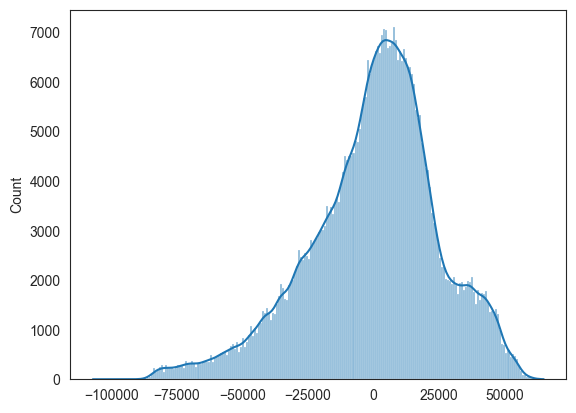

In [47]:
sns.histplot(residuals, kde=True, edgecolor='w')

## 5 – Results

| | Value |
|---|---|
| Observations | 449,514 |
| Intercept | ≈ 67,600 ¥/m² |
| Coefficient (per degree) | ≈ −207,200 ¥/m² |
| R² | 0.175 |
| p-value | < 0.001 |

**Interpretation.** The relationship is negative and highly significant. Converting degrees into metres (1° ≈ 100 km), the price drops by about **2 ¥/m² for every metre** away from a subway entrance, i.e. around **−2,000 ¥/m² per kilometre**. An apartment next to a station is estimated at ≈ 67,600 ¥/m², compared with ≈ 57,000 ¥/m² at 5 km.

**Limits.**
- Distance to the subway explains only **17.5%** of the price variance: location in the city (distance to the centre, district), surface and building quality matter a lot.
- The Durbin–Watson statistic (0.56) shows strong **spatial autocorrelation** of residuals: neighbouring apartments have similar prices, which the simple model ignores.
- Distances should ideally be computed in a metric projection (e.g. UTM zone 51N) rather than converted approximately from degrees.
- Next steps: add distance to the city centre, district fixed effects, and a log-transformed price.